# Análise descritiva preliminar: depósitos de patentes e a posição da China (1980–2024)

Exploração das quatro séries da OMPI coletadas pelo ETL do projeto (`python -m patentes.dataset` e
`python -m patentes.features`): pedidos de patente por escritório e por país de origem (1980–2024),
pedidos PCT por país de origem (1995–2024) e publicações por campo tecnológico e país de origem
(1980–2023). O foco é a posição da China e do Leste Asiático (China, Japão e Coreia do Sul) na
distribuição internacional dos depósitos.

Este notebook serve para conferir os dados e levantar padrões. As figuras e tabelas do artigo
saem só de `2.0-apj-figuras-artigo.ipynb`.

In [1]:
from pathlib import Path
import json
import sys

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pandas as pd

PROJ_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJ_ROOT))

from patentes.config import (
    ANO_FINAL_CAMPOS,
    ANO_INICIO_ORIGEM_COMPLETA,
    CODIGO_LESTE_ASIATICO,
    CODIGOS_AGREGADOS,
    ESCRITORIOS_DESTAQUE,
    INTERIM_DATA_DIR,
    MANIFEST_PATH,
    NOMES_PT,
    PAISES_DESTAQUE,
    PROCESSED_DATA_DIR,
    RAW_DATA_DIR,
)

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

2026-10-06 23:42:12.307 | INFO     | patentes.config:<module>:17 - PROJ_ROOT path is: C:\Users\ailto\1.projetos\artigo-simpori-patentes


## 1. Carregamento dos dados

O manifesto registra, para cada série, a URL da API, os filtros e a data de extração; a data
entra na legenda das figuras ("acesso em"). Em seguida, uma amostra dos CSVs **brutos**, como a
OMPI os entrega: as colunas de ano vêm em formato largo e as células vazias indicam ausência de
dado. A leitura pula as linhas de metadados do topo do arquivo.

In [2]:
manifesto = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
df_manifesto = (
    pd.DataFrame(manifesto).T
    [['descricao', 'extraido_em', 'ompi_last_updated', 'bytes']]
)
display(df_manifesto)

,descricao,extraido_em,ompi_last_updated,bytes
depositos_escritorio,Pedidos de patente (diretos + fase nacional PC...,2026-10-07T02:30:07+00:00,May 2026,147632
depositos_origem,Pedidos de patente (diretos + fase nacional PC...,2026-10-07T02:30:11+00:00,May 2026,239326
publicacoes_campo_origem,Publicações de patente por campo tecnológico (...,2026-10-07T02:30:27+00:00,May 2026,1301070
pct_origem,Pedidos PCT por data de depósito e país de ori...,2026-10-07T02:30:29+00:00,October 2026,32379


In [3]:
def ler_csv_bruto(caminho):
    linhas = caminho.read_text(encoding='utf-8-sig').splitlines()
    inicio = next(
        indice for indice, linha in enumerate(linhas)
        if linha.startswith(('Origin,', 'Office,', '"Receiving'))
    )
    return pd.read_csv(caminho, skiprows=inicio, dtype=str, keep_default_na=False, index_col=False)


df_bruto_escritorio = ler_csv_bruto(RAW_DATA_DIR / 'depositos_escritorio.csv')
df_bruto_origem = ler_csv_bruto(RAW_DATA_DIR / 'depositos_origem.csv')
df_bruto_campos = ler_csv_bruto(RAW_DATA_DIR / 'publicacoes_campo_origem.csv')
df_bruto_pct = ler_csv_bruto(RAW_DATA_DIR / 'pct_origem.csv')

In [4]:
display(df_bruto_escritorio.sample(5, random_state=42).iloc[:, :12])
display(df_bruto_origem.sample(5, random_state=42).iloc[:, :12])

,Office,Office (Code),Origin,Type,1980,1981,1982,1983,1984,1985,1986,1987
538,W2,W2,Total,Total,,,,,,,,
523,Uzbekistan,UZ,Total,Total,,,,,,,,
234,Iran (Islamic Republic of),IR,Total,Resident,169,286,202,213,162,183,,207
524,Uzbekistan,UZ,Total,Resident,,,,,,,,
486,Tonga,TO,Total,Resident,,,,,,,,


,Origin,Origin (Code),Office,Type,1980,1981,1982,1983,1984,1985,1986,1987
575,Monaco,MC,Total,Total (equivalent count),15,20,11,19,12,17,11,20
259,Denmark,DK,Total,Resident,964,1085,1095,1167,966,856,958,1007
388,Haiti,HT,Total,Total (equivalent count),4,,2,1,2,6,4,9
495,Lebanon,LB,Total,Abroad (equivalent count),,,,2,,,,2
70,Bangladesh,BD,Total,Total (equivalent count),34,39,40,40,62,40,16,23


In [5]:
display(df_bruto_campos.sample(5, random_state=42).iloc[:, :12])
display(df_bruto_pct.sample(5, random_state=42).iloc[:, :12])

,Origin,Origin (Code),Office,Field of technology,1980,1981,1982,1983,1984,1985,1986,1987
1700,El Salvador,SV,Total,"21 - Surface technology, coating",,,,,,,,
2495,Ireland,IE,Total,30 - Thermal processes and apparatus,15,17,40,22,15,22,13,28
561,Belgium,BE,Total,25 - Handling,114,98,134,114,101,101,98,58
5612,Yemen,YE,Total,"27 - Engines, pumps, turbines",,,,,,,,
5278,Uganda,UG,Total,35 - Civil engineering,,,,,,,,


,Receiving Office (RO),Receiving Office (RO)(Code),Origin,Origin(Code),1995,1996,1997,1998,1999,2000,2001,2002
175,Total,ZZ,Uganda,UG,,,,,,,,
180,Total,ZZ,Saint Vincent and the Grenadines,VC,,,2,,,1,,
111,Total,ZZ,North Macedonia,MK,1,3,5,1,7,4,3,6
65,Total,ZZ,Equatorial Guinea,GQ,,,,,,,,
101,Total,ZZ,Lithuania,LT,,4,3,2,2,1,3,10


## 2. Preparação temporal e categórica

Usa as séries já limpas pelo ETL (`data/interim/`, formato longo: uma linha por unidade, tipo e
ano) e os indicadores de `data/processed/`. Aqui só se acrescentam o nome em português, a década
e a marcação de agregados (total mundial, regiões, grupos de renda, origem desconhecida), que
não podem entrar em rankings.

In [6]:
def preparar(df):
    return df.assign(
        nome_pt=lambda d: d['codigo'].map(NOMES_PT).fillna(d['nome']),
        decada=lambda d: (d['ano'] // 10) * 10,
        eh_pais=lambda d: ~d['codigo'].isin(CODIGOS_AGREGADOS),
    )


ler = dict(keep_default_na=False, na_values=[''])  # 'NA' (Namíbia) não pode virar ausente

df_escritorio = preparar(pd.read_csv(INTERIM_DATA_DIR / 'depositos_escritorio.csv', **ler))
df_origem = preparar(pd.read_csv(INTERIM_DATA_DIR / 'depositos_origem.csv', **ler))
df_campos = preparar(pd.read_csv(INTERIM_DATA_DIR / 'publicacoes_campo_origem.csv', **ler))
df_pct = preparar(pd.read_csv(INTERIM_DATA_DIR / 'pct_origem.csv', **ler))

df_participacao_escritorio = preparar(pd.read_csv(PROCESSED_DATA_DIR / 'participacao_escritorio.csv', **ler))
df_participacao_origem = preparar(pd.read_csv(PROCESSED_DATA_DIR / 'participacao_origem.csv', **ler))
df_participacao_pct = preparar(pd.read_csv(PROCESSED_DATA_DIR / 'participacao_pct.csv', **ler))
df_concentracao = pd.read_csv(PROCESSED_DATA_DIR / 'concentracao.csv', **ler)
df_vtr = pd.read_csv(PROCESSED_DATA_DIR / 'vtr_decada.csv', **ler)
df_total_mundial = pd.read_csv(PROCESSED_DATA_DIR / 'total_mundial.csv', **ler)

display(df_origem.sample(5, random_state=42))

,nome,codigo,tipo,ano,valor,nome_pt,decada,eh_pais
15316,Viet Nam,VN,Exterior (contagem equivalente),2012,46.0,Viet Nam,2010,True
16115,Bahamas,BS,Total (contagem equivalente),2014,140.0,Bahamas,2010,True
7484,Romania,RO,Exterior (contagem equivalente),2000,25.0,Romania,2000,True
3494,New Zealand,NZ,Total,1991,985.0,New Zealand,1990,True
10963,Georgia,GE,Total,2006,249.0,Georgia,2000,True


In [7]:
cobertura_series = pd.DataFrame({
    nome: {
        'ano_inicial': df['ano'].min(),
        'ano_final': df['ano'].max(),
        'n_unidades': df.loc[df['eh_pais'], 'codigo'].nunique(),
        'n_linhas': len(df),
    }
    for nome, df in {
        'escritorio': df_escritorio,
        'origem': df_origem,
        'campos': df_campos,
        'pct': df_pct,
    }.items()
}).T
display(cobertura_series)
display(df_total_mundial.groupby('fonte')['ano'].agg(['min', 'max']))

,ano_inicial,ano_final,n_unidades,n_linhas
escritorio,1980,2024,181,15323
origem,1980,2024,206,24557
campos,1980,2024,206,113721
pct,1995,2024,182,3678


,min,max
fonte,,
WD (OMPI),1985,2024
soma dos escritórios,1980,1984


## 3. Séries temporais

Volume de pedidos (em milhares) nos cinco principais escritórios e nos cinco principais países de
origem. Na série por origem, a linha vertical marca 1994: antes desse ano a OMPI não cruza
escritório e origem, e os depósitos feitos no exterior ficam quase todos sem origem identificada
(ver seção 10.2).

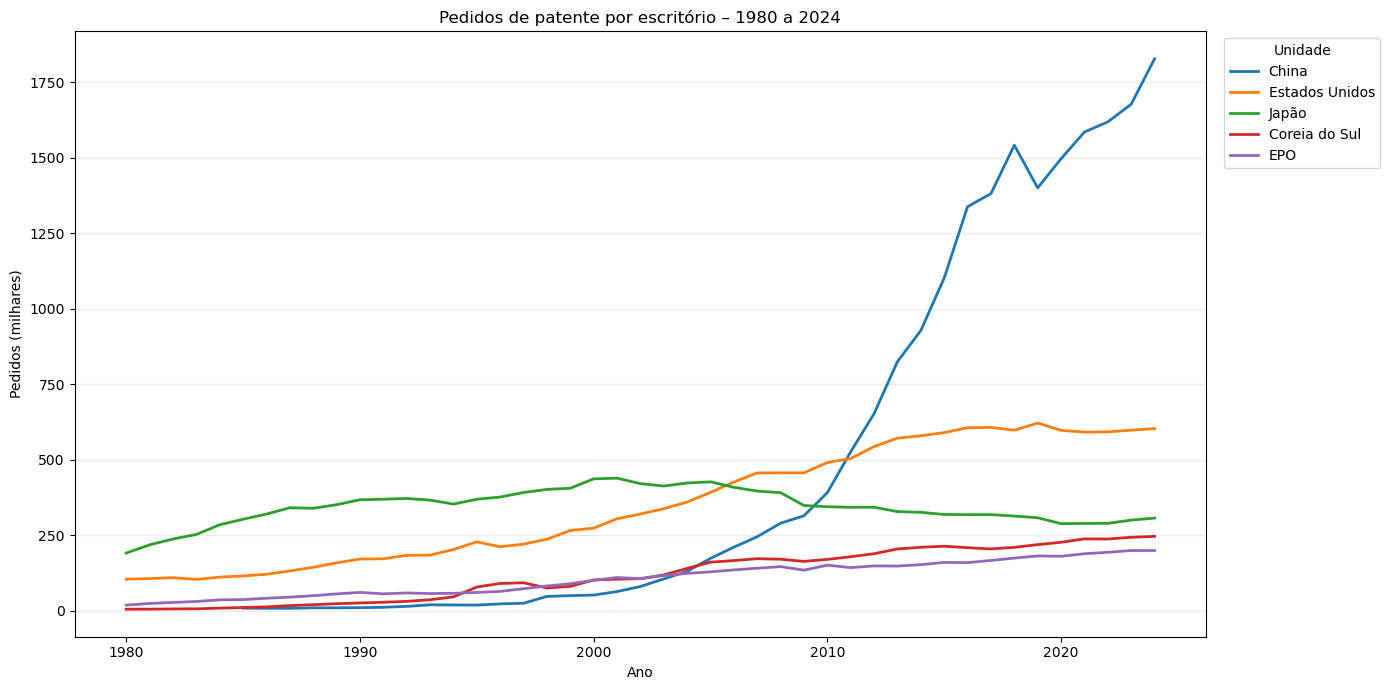

In [8]:
def plotar_series(df, codigos, coluna_valor, titulo, rotulo_y, escala=1, linha_vertical=None):
    fig, ax = plt.subplots(figsize=(14, 7))
    for codigo in codigos:
        serie = df.loc[df['codigo'] == codigo].sort_values('ano')
        ax.plot(serie['ano'], serie[coluna_valor] / escala, linewidth=2, label=NOMES_PT.get(codigo, codigo))
    if linha_vertical:
        ax.axvline(linha_vertical, color='grey', linestyle=':', linewidth=1.2)
    ax.set_title(titulo)
    ax.set_xlabel('Ano')
    ax.set_ylabel(rotulo_y)
    ax.grid(True, axis='y', alpha=0.25)
    ax.legend(title='Unidade', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout()
    return ax


df_escritorio_total = df_escritorio.loc[df_escritorio['tipo'] == 'Total']
df_origem_total = df_origem.loc[df_origem['tipo'] == 'Total']

plotar_series(
    df_escritorio_total, ESCRITORIOS_DESTAQUE, 'valor',
    'Pedidos de patente por escritório – 1980 a 2024', 'Pedidos (milhares)', escala=1_000,
);

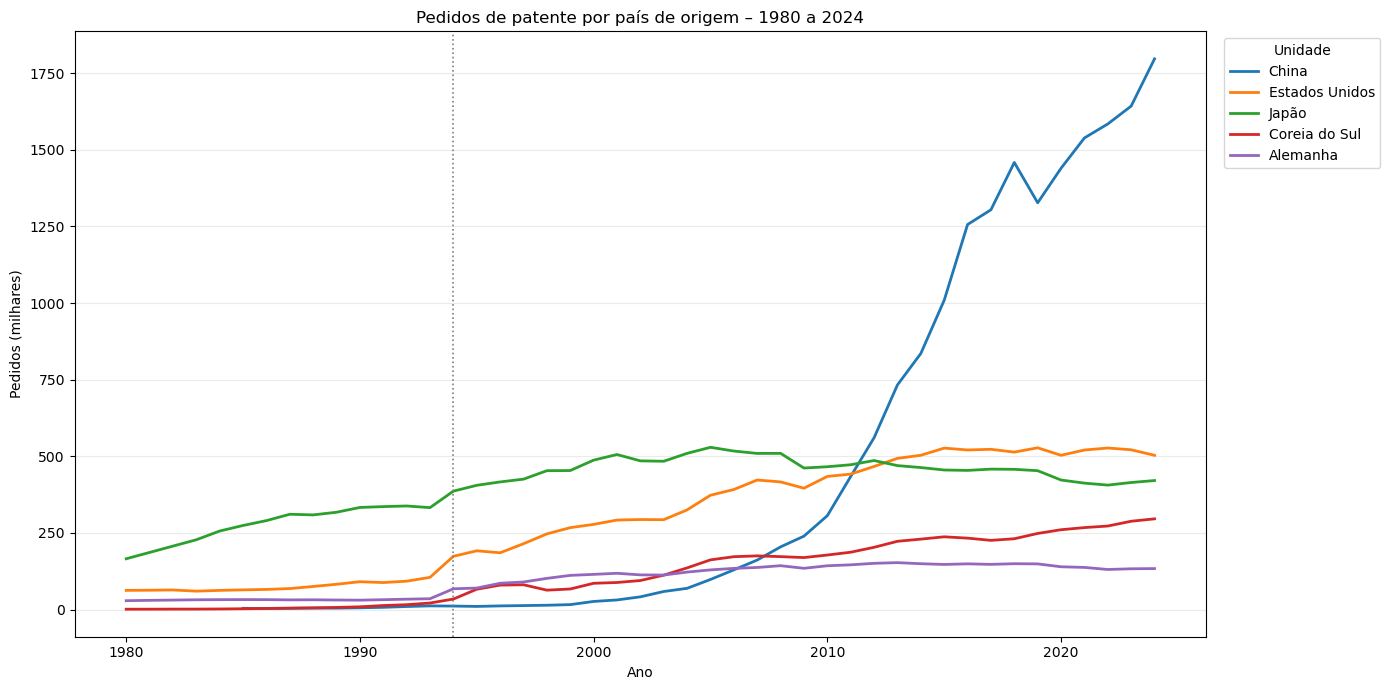

In [9]:
plotar_series(
    df_origem_total, PAISES_DESTAQUE, 'valor',
    'Pedidos de patente por país de origem – 1980 a 2024', 'Pedidos (milhares)', escala=1_000,
    linha_vertical=ANO_INICIO_ORIGEM_COMPLETA,
);

## 4. Agregados por década e rankings top-N

Soma dos pedidos por década e os dez maiores escritórios e países de origem em 2024. A posição da
China em cada ano (rank entre países) resume a trajetória que o artigo descreve.

In [10]:
df_escritorio_decada = (
    df_escritorio_total.loc[df_escritorio_total['eh_pais']]
    .groupby(['decada', 'codigo', 'nome_pt'], as_index=False)['valor']
    .sum()
)
top5_escritorios_por_decada = (
    df_escritorio_decada
    .sort_values(['decada', 'valor'], ascending=[True, False])
    .groupby('decada')
    .head(5)
    .assign(valor_milhares=lambda d: (d['valor'] / 1_000).round(1))
    [['decada', 'nome_pt', 'valor_milhares']]
)
display(top5_escritorios_por_decada)

,decada,nome_pt,valor_milhares
57,1980,Japão,2839.0
99,1980,Soviet Union,1617.5
109,1980,Estados Unidos,1205.9
26,1980,Alemanha,445.9
32,1980,EPO,365.7
186,1990,Japão,3773.7
253,1990,Estados Unidos,2076.9
160,1990,EPO,659.4
191,1990,Coreia do Sul,584.6
152,1990,Alemanha,477.0


In [11]:
top10_escritorios_2024 = (
    df_participacao_escritorio
    .loc[df_participacao_escritorio['eh_pais'] & (df_participacao_escritorio['ano'] == 2024)]
    .sort_values('participacao', ascending=False)
    .head(10)
    .assign(participacao=lambda d: d['participacao'].round(1))
    [['nome_pt', 'valor', 'participacao']]
)
top10_origens_2024 = (
    df_participacao_origem
    .loc[df_participacao_origem['eh_pais'] & (df_participacao_origem['ano'] == 2024)]
    .sort_values('participacao', ascending=False)
    .head(10)
    .assign(participacao=lambda d: d['participacao'].round(1))
    [['nome_pt', 'valor', 'participacao']]
)
display(top10_escritorios_2024)
display(top10_origens_2024)

,nome_pt,valor,participacao
909,China,1828054.0,49.1
4981,Estados Unidos,603194.0,16.2
2518,Japão,306855.0,8.2
2683,Coreia do Sul,246245.0,6.6
1499,EPO,199402.0,5.4
2250,India,105157.0,2.8
1179,Alemanha,59262.0,1.6
770,Canada,35374.0,0.9
277,Australia,30487.0,0.8
4269,Russian Federation,26698.0,0.7


,nome_pt,valor,participacao
955,China,1796738.0,48.2
4589,Estados Unidos,503283.0,13.5
2425,Japão,420991.0,11.3
2565,Coreia do Sul,296041.0,7.9
1209,Alemanha,133790.0,3.6
2181,India,76473.0,2.1
1634,França,51880.0,1.4
1700,Reino Unido,46840.0,1.3
829,Switzerland,41341.0,1.1
3397,Netherlands (Kingdom of the),26445.0,0.7


In [12]:
def posicao_no_ranking(df_participacao, codigo):
    return (
        df_participacao.loc[df_participacao['eh_pais']]
        .assign(posicao=lambda d: d.groupby('ano')['participacao'].rank(method='min', ascending=False))
        .loc[lambda d: d['codigo'] == codigo]
        .set_index('ano')['posicao']
    )


posicao_china = pd.DataFrame({
    'escritorio': posicao_no_ranking(df_participacao_escritorio, 'CN'),
    'origem': posicao_no_ranking(df_participacao_origem, 'CN'),
    'pct': posicao_no_ranking(df_participacao_pct, 'CN'),
})
display(posicao_china.loc[[1985, 1990, 1995, 2000, 2005, 2010, 2011, 2015, 2019, 2020, 2024]])

,escritorio,origem,pct
ano,,,
1985,15.0,10.0,NaN
1990,11.0,8.0,NaN
1995,9.0,9.0,22.0
2000,6.0,7.0,16.0
2005,3.0,5.0,10.0
2010,2.0,3.0,4.0
2011,1.0,3.0,4.0
2015,1.0,1.0,3.0
2019,1.0,1.0,1.0


## 5. Estatística descritiva

Distribuição das participações anuais no total mundial dos pedidos (por escritório) para os
principais escritórios. O coeficiente de variação compara a instabilidade relativa de
participações com escalas muito diferentes (a da China vai de menos de 1% a quase metade do
total).

In [13]:
resumo_participacao_escritorio = (
    df_participacao_escritorio
    .loc[df_participacao_escritorio['codigo'].isin(ESCRITORIOS_DESTAQUE + [CODIGO_LESTE_ASIATICO])]
    .groupby('nome_pt')['participacao']
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(1)
    .rename(columns={
        'count': 'n_obs', 'mean': 'media', 'std': 'desvio_padrao',
        'min': 'minimo', '25%': 'q1', '50%': 'mediana', '75%': 'q3', 'max': 'maximo',
    })
)
resumo_participacao_escritorio['coeficiente_variacao'] = (
    resumo_participacao_escritorio['desvio_padrao'] / resumo_participacao_escritorio['media']
).round(2)
display(resumo_participacao_escritorio)

,n_obs,media,desvio_padrao,minimo,q1,mediana,q3,maximo,coeficiente_variacao
nome_pt,,,,,,,,,
China,40.0,17.8,18.1,0.8,2.1,9.2,35.5,49.1,1.02
Coreia do Sul,45.0,5.8,2.9,0.6,3.2,6.8,8.0,9.4,0.50
EPO,45.0,5.9,1.4,2.3,5.3,5.8,7.0,7.9,0.24
Estados Unidos,45.0,19.0,3.8,12.2,16.8,19.4,22.3,24.6,0.20
Japão,45.0,24.3,10.7,8.2,12.8,26.9,33.6,41.6,0.44
Leste Asiático,45.0,45.8,10.2,24.0,42.3,44.2,53.0,63.9,0.22


In [14]:
resumo_participacao_pct = (
    df_participacao_pct
    .loc[df_participacao_pct['codigo'].isin(PAISES_DESTAQUE + [CODIGO_LESTE_ASIATICO])]
    .groupby('nome_pt')['participacao']
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(1)
    .rename(columns={
        'count': 'n_obs', 'mean': 'media', 'std': 'desvio_padrao',
        'min': 'minimo', '25%': 'q1', '50%': 'mediana', '75%': 'q3', 'max': 'maximo',
    })
)
resumo_participacao_pct['coeficiente_variacao'] = (
    resumo_participacao_pct['desvio_padrao'] / resumo_participacao_pct['media']
).round(2)
display(resumo_participacao_pct)

,n_obs,media,desvio_padrao,minimo,q1,mediana,q3,maximo,coeficiente_variacao
nome_pt,,,,,,,,,
Alemanha,30.0,10.2,2.7,6.1,7.8,10.7,12.8,14.0,0.26
China,30.0,9.8,9.7,0.3,1.2,6.3,19.7,25.5,0.99
Coreia do Sul,30.0,4.7,2.6,0.5,2.4,5.4,6.7,8.7,0.55
Estados Unidos,30.0,30.8,7.9,19.8,23.5,29.0,37.0,43.2,0.26
Japão,30.0,16.4,4.5,6.9,13.3,18.1,19.6,22.3,0.27
Leste Asiático,30.0,30.9,15.4,7.7,16.7,31.2,45.9,51.9,0.50


## 6. KPIs de variação e participação

Com dados anuais, a variação "mês a mês" do padrão vira variação anual e a "interanual" vira
variação em dez anos. Participações e suas diferenças em pontos percentuais (p.p.) vêm dos
indicadores do ETL.

In [15]:
df_kpis_escritorio = (
    df_participacao_escritorio
    .loc[df_participacao_escritorio['codigo'].isin(ESCRITORIOS_DESTAQUE + [CODIGO_LESTE_ASIATICO])]
    .sort_values(['codigo', 'ano'])
    .copy()
)
df_kpis_escritorio['variacao_anual'] = (
    df_kpis_escritorio.groupby('codigo')['valor'].pct_change(periods=1).mul(100).round(1)
)
df_kpis_escritorio['variacao_10_anos'] = (
    df_kpis_escritorio.groupby('codigo')['valor'].pct_change(periods=10).mul(100).round(1)
)
df_kpis_escritorio['variacao_participacao_10_anos_pp'] = (
    df_kpis_escritorio.groupby('codigo')['participacao'].diff(periods=10).round(1)
)
display(
    df_kpis_escritorio
    .loc[df_kpis_escritorio['ano'].isin([2004, 2014, 2024])]
    .assign(participacao=lambda d: d['participacao'].round(1))
    [['ano', 'nome_pt', 'valor', 'participacao', 'variacao_anual', 'variacao_10_anos',
      'variacao_participacao_10_anos_pp']]
)

,ano,nome_pt,valor,participacao,variacao_anual,variacao_10_anos,variacao_participacao_10_anos_pp
889,2004,China,130384.0,8.3,23.8,583.8,6.3
899,2014,China,928177.0,34.6,12.5,611.9,26.3
909,2024,China,1828054.0,49.1,9.0,97.0,14.4
1479,2004,EPO,123701.0,7.9,6.1,113.9,1.7
1489,2014,EPO,152662.0,5.7,3.2,23.4,-2.2
1499,2024,EPO,199402.0,5.4,-0.0,30.6,-0.3
2498,2004,Japão,423081.0,26.9,2.4,19.8,-10.5
2508,2014,Japão,325989.0,12.2,-0.7,-22.9,-14.8
2518,2024,Japão,306855.0,8.2,2.2,-5.9,-3.9
2663,2004,Coreia do Sul,140115.0,8.9,18.1,206.5,4.1


In [16]:
participacao_leste_asiatico = pd.DataFrame({
    'escritorio': df_participacao_escritorio.query("codigo == @CODIGO_LESTE_ASIATICO").set_index('ano')['participacao'],
    'origem': df_participacao_origem.query("codigo == @CODIGO_LESTE_ASIATICO").set_index('ano')['participacao'],
    'pct': df_participacao_pct.query("codigo == @CODIGO_LESTE_ASIATICO").set_index('ano')['participacao'],
}).round(1)
display(participacao_leste_asiatico.loc[[1980, 1985, 1990, 1995, 1998, 2000, 2005, 2010, 2015, 2020, 2024]])

,escritorio,origem,pct
ano,,,
1980,24.0,20.4,NaN
1985,34.9,30.5,NaN
1990,40.5,34.9,NaN
1995,44.5,46.0,7.7
1998,43.2,43.7,10.4
2000,43.1,43.7,12.8
2005,44.7,46.3,23.4
2010,45.3,47.6,32.9
2015,56.6,59.0,40.7


## 7. Distribuição: histogramas e boxplots

O histograma mostra como a variação anual dos pedidos se distribui entre todos os escritórios com
pelo menos mil pedidos no ano (2000–2024). O boxplot compara a dispersão dessa variação entre os
principais escritórios (1990–2024): a China combina mediana alta com poucas quedas.

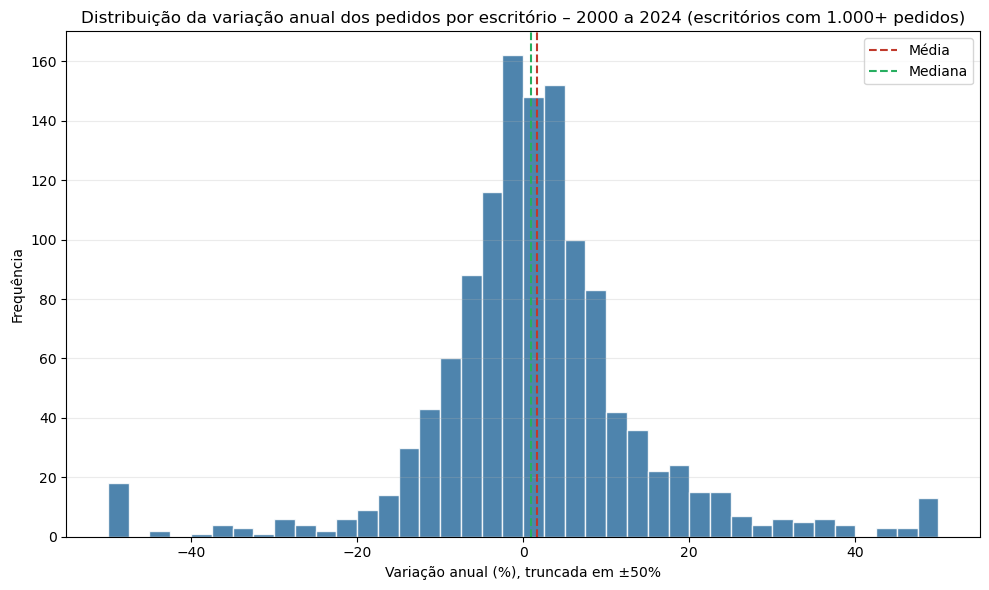

In [17]:
df_variacao_escritorios = (
    df_escritorio_total.loc[df_escritorio_total['eh_pais']]
    .sort_values(['codigo', 'ano'])
    .assign(
        variacao_anual=lambda d: d.groupby('codigo')['valor'].pct_change(periods=1).mul(100),
        valor_ano_anterior=lambda d: d.groupby('codigo')['valor'].shift(1),
    )
    .loc[lambda d: d['ano'].between(2000, 2024) & (d['valor_ano_anterior'] >= 1_000)]
    .dropna(subset=['variacao_anual'])
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(df_variacao_escritorios['variacao_anual'].clip(-50, 50), bins=40, color='#2f6f9f', edgecolor='white', alpha=0.85)
ax.axvline(df_variacao_escritorios['variacao_anual'].mean(), color='#c0392b', linestyle='--', linewidth=1.5, label='Média')
ax.axvline(df_variacao_escritorios['variacao_anual'].median(), color='#27ae60', linestyle='--', linewidth=1.5, label='Mediana')
ax.set_title('Distribuição da variação anual dos pedidos por escritório – 2000 a 2024 (escritórios com 1.000+ pedidos)')
ax.set_xlabel('Variação anual (%), truncada em ±50%')
ax.set_ylabel('Frequência')
ax.grid(True, axis='y', alpha=0.25)
ax.legend()
plt.tight_layout()

,count,mean,std,min,25%,50%,75%,max
nome_pt,,,,,,,,
China,35.0,17.2,17.3,-9.2,5.7,16.5,24.2,91.3
Coreia do Sul,35.0,7.7,14.0,-18.8,2.0,4.0,10.6,71.7
EPO,35.0,3.8,5.4,-7.9,0.8,4.1,5.9,13.9
Estados Unidos,35.0,4.0,4.6,-7.1,0.5,4.0,7.5,12.5
Japão,35.0,-0.3,3.4,-10.8,-1.8,0.0,1.5,7.7


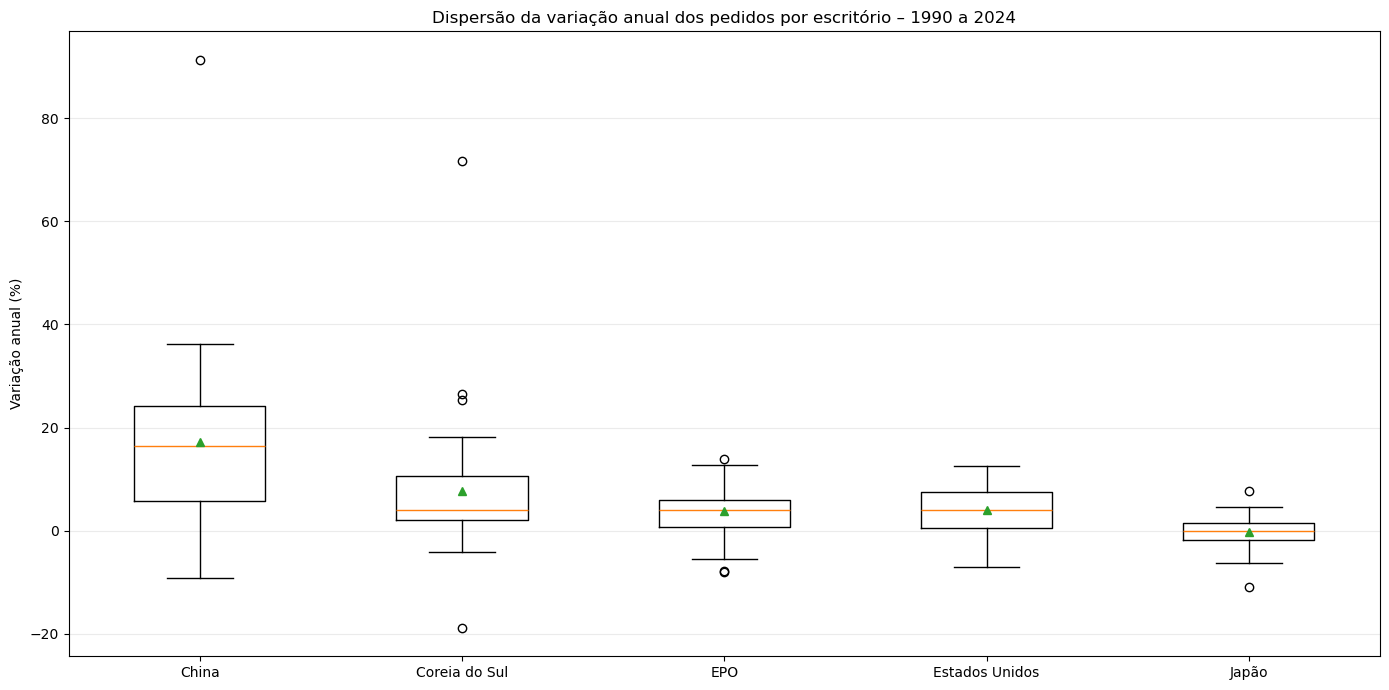

In [18]:
df_variacao_destaque = (
    df_escritorio_total
    .loc[df_escritorio_total['codigo'].isin(ESCRITORIOS_DESTAQUE)]
    .sort_values(['codigo', 'ano'])
    .assign(variacao_anual=lambda d: d.groupby('codigo')['valor'].pct_change(periods=1).mul(100))
    .loc[lambda d: d['ano'].between(1990, 2024)]
    .dropna(subset=['variacao_anual'])
)
grupos_boxplot = [dados['variacao_anual'].values for _, dados in df_variacao_destaque.groupby('nome_pt')]
rotulos_boxplot = [nome for nome, _ in df_variacao_destaque.groupby('nome_pt')]

fig, ax = plt.subplots(figsize=(14, 7))
ax.boxplot(grupos_boxplot, tick_labels=rotulos_boxplot, showmeans=True)
ax.set_title('Dispersão da variação anual dos pedidos por escritório – 1990 a 2024')
ax.set_ylabel('Variação anual (%)')
ax.grid(True, axis='y', alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()

display(
    df_variacao_destaque.groupby('nome_pt')['variacao_anual']
    .describe(percentiles=[0.25, 0.5, 0.75]).round(1)
)

## 8. Média móvel de três anos

Com dados anuais não há sazonalidade a remover; a média móvel de três anos atenua quebras pontuais,
como a queda do escritório chinês em 2019, ano seguinte à mudança de critério de contagem
(a partir de 2017 só entram pedidos com taxa paga; ver seção 7.4 do CLAUDE.md).

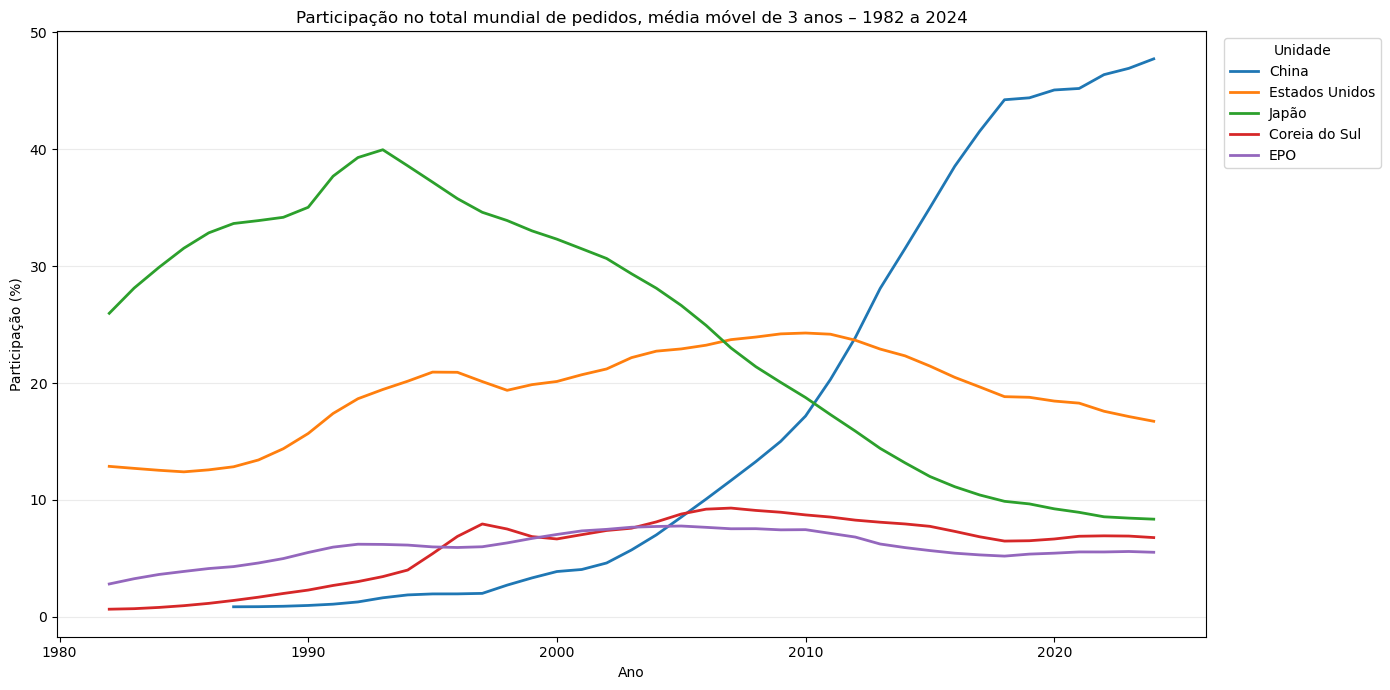

In [19]:
df_media_movel = (
    df_participacao_escritorio
    .loc[df_participacao_escritorio['codigo'].isin(ESCRITORIOS_DESTAQUE)]
    .sort_values(['codigo', 'ano'])
    .copy()
)
df_media_movel['participacao_media_movel_3a'] = (
    df_media_movel.groupby('codigo')['participacao']
    .transform(lambda serie: serie.rolling(3, min_periods=3).mean())
)
plotar_series(
    df_media_movel, ESCRITORIOS_DESTAQUE, 'participacao_media_movel_3a',
    'Participação no total mundial de pedidos, média móvel de 3 anos – 1982 a 2024', 'Participação (%)',
);

## 9. Variação em relação à média histórica

Para cada escritório, compara o volume de cada ano com a média e o desvio-padrão dos anos
anteriores (`expanding().shift(1)`, mínimo de cinco anos), o que evita usar o próprio ano no
cálculo. O desvio percentual é a medida legível; o z-score aponta os anos fora do padrão da
própria série.

In [20]:
df_historico = df_kpis_escritorio.loc[df_kpis_escritorio['codigo'] != CODIGO_LESTE_ASIATICO].sort_values(['codigo', 'ano']).copy()

media_historica = (
    df_historico.groupby('codigo')['valor']
    .transform(lambda serie: serie.expanding(min_periods=5).mean().shift(1))
)
desvio_padrao_historico = (
    df_historico.groupby('codigo')['valor']
    .transform(lambda serie: serie.expanding(min_periods=5).std().shift(1))
)
df_historico['desvio_pct_media_historica'] = ((df_historico['valor'] / media_historica - 1) * 100).round(1)
df_historico['z_score_media_historica'] = ((df_historico['valor'] - media_historica) / desvio_padrao_historico).round(2)

display(
    df_historico.loc[df_historico['ano'].isin([2005, 2010, 2015, 2020, 2024])]
    .pivot(index='ano', columns='nome_pt', values='desvio_pct_media_historica')
)
display(
    df_historico.loc[df_historico['z_score_media_historica'].abs() > 3,
                     ['ano', 'nome_pt', 'valor', 'desvio_pct_media_historica', 'z_score_media_historica']]
    .sort_values(['nome_pt', 'ano'])
)

nome_pt,China,Coreia do Sul,EPO,Estados Unidos,Japão
ano,,,,,
2005,385.8,216.5,103.4,100.9,22.1
2010,402.3,142.4,99.7,108.3,-3.5
2015,527.2,144.6,86.0,111.7,-10.1
2020,335.4,120.5,87.2,87.0,-17.5
2024,287.2,114.1,90.1,75.1,-10.9


,ano,nome_pt,valor,desvio_pct_media_historica,z_score_media_historica
877,1992,China,14409.0,54.0,4.08
878,1993,China,19618.0,96.4,4.54
883,1998,China,47396.0,233.4,5.53
884,1999,China,50044.0,201.7,3.16
887,2002,China,80232.0,243.0,3.14
888,2003,China,105317.0,296.7,3.57
889,2004,China,130384.0,324.8,3.55
890,2005,China,173327.0,385.8,3.91
891,2006,China,210501.0,398.4,3.69
892,2007,China,245161.0,391.5,3.41


## 10. Comparações específicas

### 10.1 Concentração: CR5 e HHI

CR5 e HHI calculados sobre as participações no total mundial. Atenção à direção do HHI: entre os
escritórios ele **sobe** desde 2010 (a China concentra quase metade dos pedidos), enquanto no PCT
ele **cai**. A frase do resumo e da seção 3 do CLAUDE.md ("a concentração sobe, mas o HHI cai")
vale para o PCT, não para os escritórios.

cr5                     hhi                
serie escritorio origem   pct escritorio  origem     pct
ano                                                     
1980        67.8   54.1   NaN     1242.3   901.0     NaN
1990        75.7   58.9   NaN     1874.2  1345.5     NaN
1995        74.7   73.0  74.7     1854.4  1939.3  2171.5
2000        71.1   73.5  74.1     1586.3  1815.7  2040.8
2005        75.2   75.8  72.1     1440.3  1649.9  1724.9
2010        77.4   76.5  71.0     1441.7  1407.4  1397.8
2015        82.6   82.3  75.3     2098.6  1910.7  1445.6
2020        85.0   84.3  78.8     2579.0  2416.9  1544.9
2024        85.5   84.6  77.8     2825.6  2725.2  1500.1

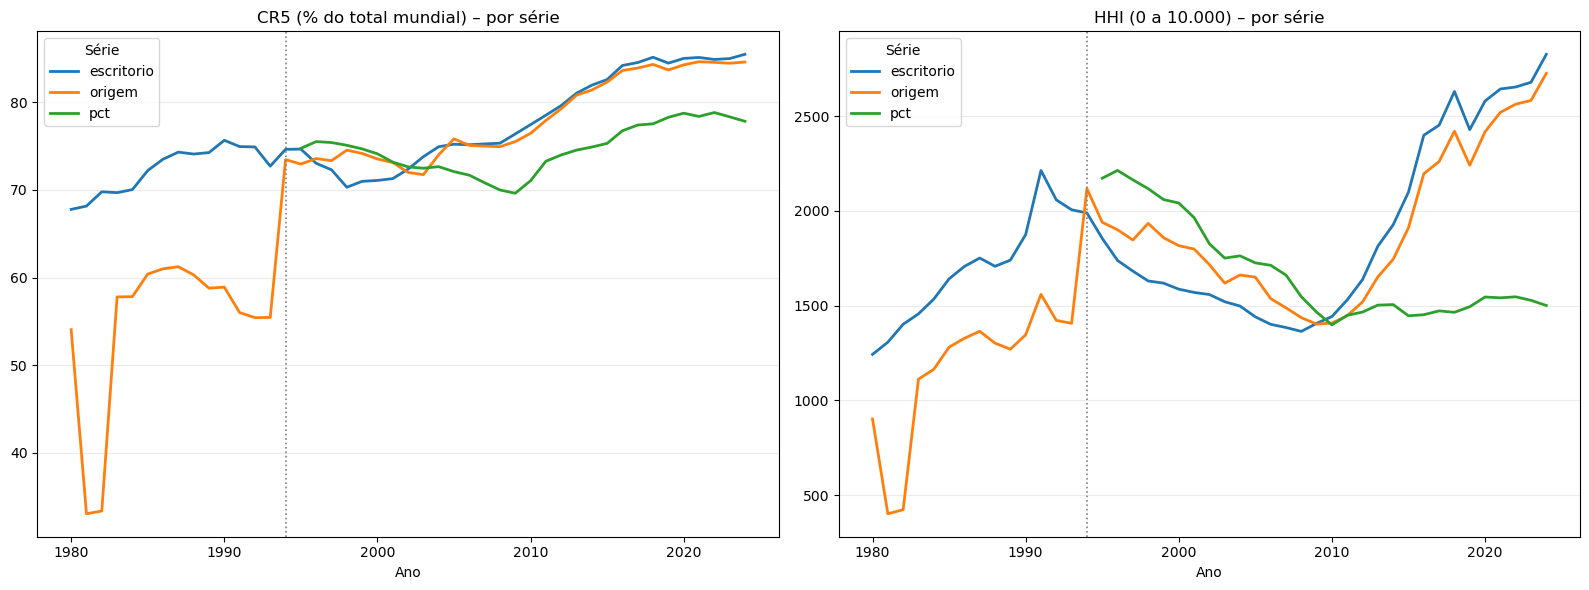

In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 6))
for serie, dados in df_concentracao.groupby('serie'):
    eixos[0].plot(dados['ano'], dados['cr5'], linewidth=2, label=serie)
    eixos[1].plot(dados['ano'], dados['hhi'], linewidth=2, label=serie)
eixos[0].set_title('CR5 (% do total mundial) – por série')
eixos[1].set_title('HHI (0 a 10.000) – por série')
for ax in eixos:
    ax.axvline(ANO_INICIO_ORIGEM_COMPLETA, color='grey', linestyle=':', linewidth=1.2)
    ax.grid(True, axis='y', alpha=0.25)
    ax.set_xlabel('Ano')
    ax.legend(title='Série')
plt.tight_layout()

display(
    df_concentracao.loc[df_concentracao['ano'].isin([1980, 1990, 1995, 2000, 2005, 2010, 2015, 2020, 2024])]
    .pivot(index='ano', columns='serie', values=['cr5', 'hhi'])
    .round(1)
)

In [22]:
display(
    df_concentracao.groupby(['serie', 'lider'])['ano'].agg(['min', 'max', 'count'])
)

min   max  count
serie      lider                   
escritorio CN     2011  2024     14
           JP     1980  2005     26
           US     2006  2010      5
origem     CN     2012  2024     13
           JP     1980  2011     30
           SU     1981  1982      2
pct        CN     2019  2024      6
           US     1995  2018     24

### 10.2 Cobertura da série por país de origem

Peso da origem desconhecida (`**`) no total mundial de pedidos. Até 1993 ela fica em torno de um
terço do total, porque a OMPI ainda não cruzava escritório e origem: o que um país depositou no
exterior não é atribuído a ele. **Participações por origem anteriores a 1994 subestimam os países
que depositam fora (Japão, EUA, Alemanha) e não são comparáveis às posteriores.** A segunda tabela
confere que a soma das origens reproduz o total mundial.

,soma_origens,total_mundial,fonte,diferenca_pct
ano,,,,
1980,798872.0,817524.0,soma dos escritórios,-2.28
1985,884379.0,921800.0,WD (OMPI),-4.06
1990,935170.0,997500.0,WD (OMPI),-6.25
1994,944106.0,942800.0,WD (OMPI),0.14
2000,1363374.0,1371900.0,WD (OMPI),-0.62
2010,1990357.0,1998300.0,WD (OMPI),-0.40
2020,3280513.0,3282600.0,WD (OMPI),-0.06
2024,3721877.0,3725000.0,WD (OMPI),-0.08


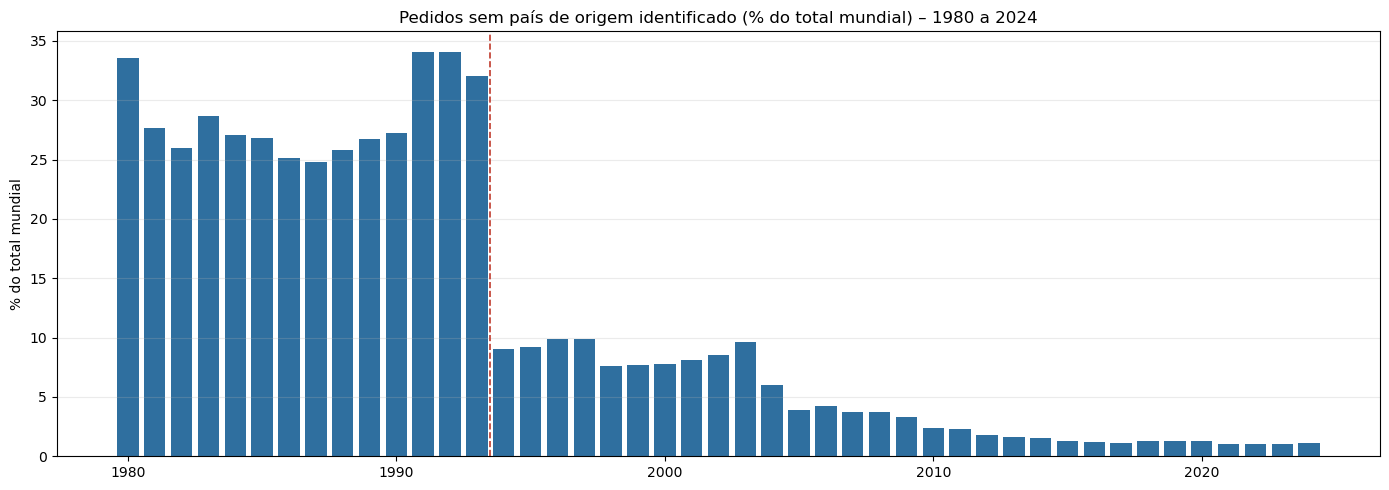

In [23]:
participacao_origem_desconhecida = (
    df_participacao_origem.loc[df_participacao_origem['codigo'] == '**']
    .set_index('ano')['participacao']
    .round(1)
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(participacao_origem_desconhecida.index, participacao_origem_desconhecida.values, color='#2f6f9f')
ax.axvline(ANO_INICIO_ORIGEM_COMPLETA - 0.5, color='#c0392b', linestyle='--', linewidth=1.2)
ax.set_title('Pedidos sem país de origem identificado (% do total mundial) – 1980 a 2024')
ax.set_ylabel('% do total mundial')
ax.grid(True, axis='y', alpha=0.25)
plt.tight_layout()

soma_origens_vs_mundo = (
    df_origem_total.loc[df_origem_total['eh_pais'] | (df_origem_total['codigo'] == '**')]
    .groupby('ano')['valor'].sum()
    .to_frame('soma_origens')
    .join(df_total_mundial.set_index('ano')[['valor', 'fonte']].rename(columns={'valor': 'total_mundial'}))
    .assign(diferenca_pct=lambda d: ((d['soma_origens'] / d['total_mundial'] - 1) * 100).round(2))
)
display(soma_origens_vs_mundo.loc[[1980, 1985, 1990, 1994, 2000, 2010, 2020, 2024]])

### 10.3 PCT por país de origem

Participação no total de pedidos PCT. Os valores de 1998, 2005 e 2024 são os que o resumo cita
(seção 8 do CLAUDE.md), recalculados com a versão atual da base.

In [24]:
participacao_pct_destaque = (
    df_participacao_pct
    .loc[df_participacao_pct['codigo'].isin(PAISES_DESTAQUE + [CODIGO_LESTE_ASIATICO])]
    .pivot(index='ano', columns='nome_pt', values='participacao')
    .round(1)
)
display(participacao_pct_destaque.loc[[1995, 1998, 2000, 2005, 2010, 2015, 2019, 2020, 2024]])

nome_pt,Alemanha,China,Coreia do Sul,Estados Unidos,Japão,Leste Asiático
ano,,,,,,
1995,12.8,0.3,0.5,42.8,6.9,7.7
1998,14.0,0.5,0.8,41.7,9.1,10.4
2000,13.5,0.8,1.7,40.8,10.3,12.8
2005,11.7,1.8,3.4,34.3,18.2,23.4
2010,10.7,7.5,5.8,27.4,19.6,32.9
2015,8.3,13.7,6.7,26.3,20.3,40.7
2019,7.3,22.3,7.2,21.6,19.9,49.3
2020,6.7,25.1,7.3,21.3,18.4,50.8
2024,6.1,25.5,8.7,19.8,17.7,51.9


### 10.4 Especialização tecnológica da China (VTR)

VTR por campo e década, com somas decenais (seção 7.3 do CLAUDE.md). Valores acima de 1 indicam
especialização relativa. O mapa usa escala divergente centrada em 1, em vez da escala `Blues` do
padrão, porque o que importa é o lado do limiar em que cada campo está. A década 1984–1993 herda
o problema de cobertura da seção 10.2.

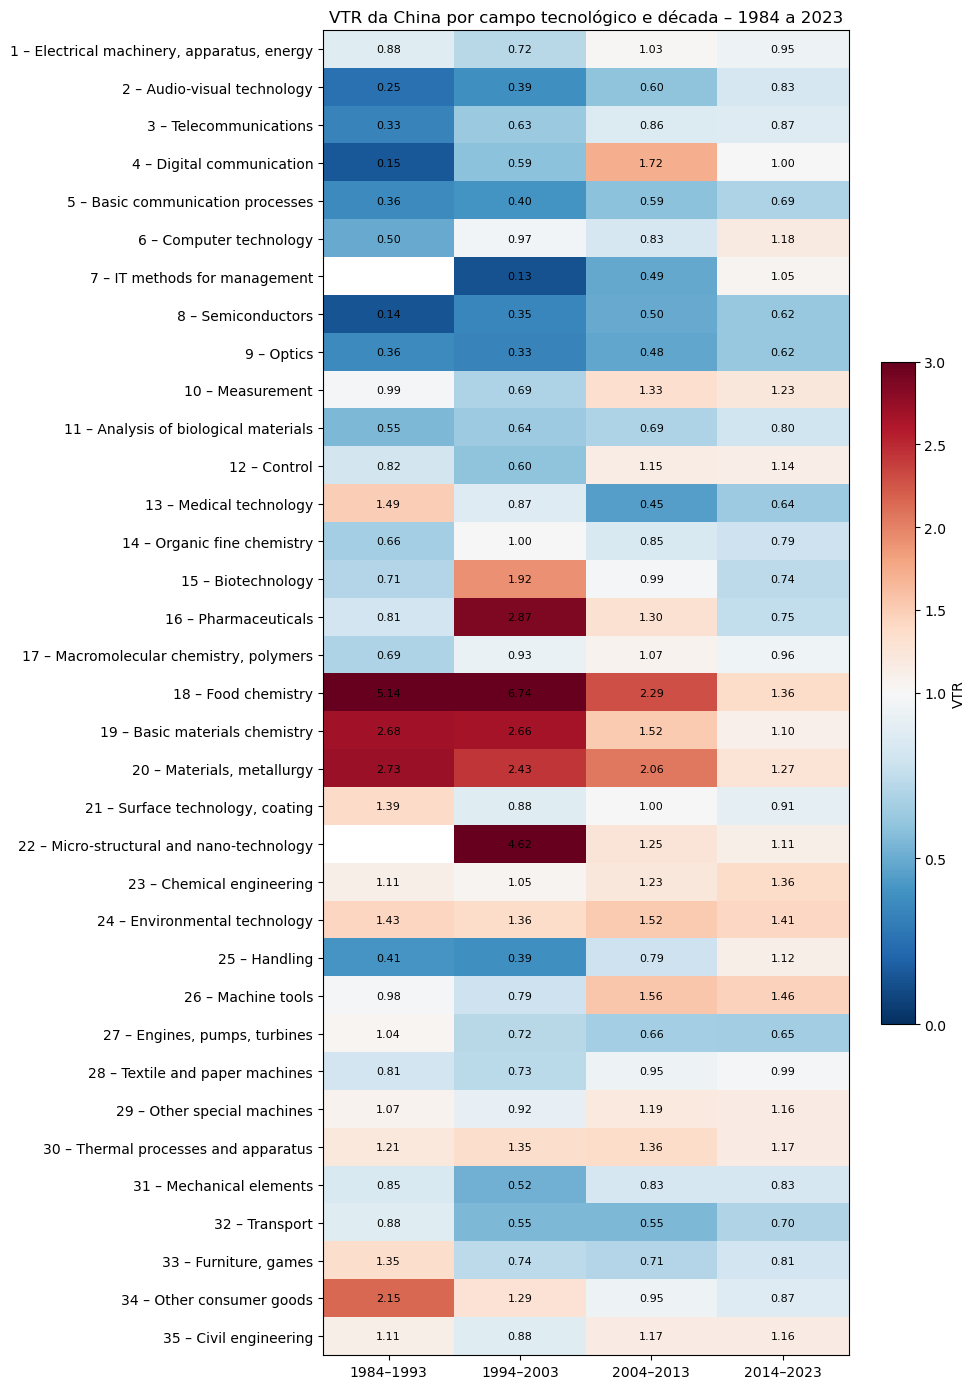

In [25]:
vtr_china = (
    df_vtr.loc[df_vtr['codigo'] == 'CN']
    .pivot(index=['campo', 'nome_campo'], columns='decada', values='vtr')
    .round(2)
)

fig, ax = plt.subplots(figsize=(10, 14))
imagem = ax.imshow(vtr_china.values, cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=1, vmin=0, vmax=3), aspect='auto')
ax.set_xticks(range(len(vtr_china.columns)), vtr_china.columns)
ax.set_yticks(range(len(vtr_china)), [f'{campo} – {nome}' for campo, nome in vtr_china.index])
for linha in range(vtr_china.shape[0]):
    for coluna in range(vtr_china.shape[1]):
        valor = vtr_china.iat[linha, coluna]
        if pd.notna(valor):
            ax.text(coluna, linha, f'{valor:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('VTR da China por campo tecnológico e década – 1984 a 2023')
ax.grid(False)
fig.colorbar(imagem, ax=ax, shrink=0.5, label='VTR')
plt.tight_layout()

In [26]:
peso_mundial_ultima_decada = (
    df_vtr.loc[df_vtr['decada'] == df_vtr['decada'].max()]
    .drop_duplicates('campo')
    .set_index(['campo', 'nome_campo'])['participacao_campo_no_mundo']
    .sort_values(ascending=False)
    .round(1)
)
top10_campos = peso_mundial_ultima_decada.head(10)
display(
    vtr_china.loc[top10_campos.index]
    .assign(peso_mundial_ultima_decada=top10_campos)
)

,decada,1984–1993,1994–2003,2004–2013,2014–2023,peso_mundial_ultima_decada
campo,nome_campo,,,,,
6,Computer technology,0.50,0.97,0.83,1.18,9.5
1,"Electrical machinery, apparatus, energy",0.88,0.72,1.03,0.95,6.8
10,Measurement,0.99,0.69,1.33,1.23,5.5
4,Digital communication,0.15,0.59,1.72,1.00,5.1
13,Medical technology,1.49,0.87,0.45,0.64,4.9
32,Transport,0.88,0.55,0.55,0.70,4.3
29,Other special machines,1.07,0.92,1.19,1.16,3.7
35,Civil engineering,1.11,0.88,1.17,1.16,3.7
16,Pharmaceuticals,0.81,2.87,1.30,0.75,3.4


In [27]:
publicacoes_por_ano = (
    df_campos.loc[df_campos['eh_pais'] & (df_campos['campo'] != 0)]
    .groupby('ano')['valor'].sum()
)
display(publicacoes_por_ano.loc[2019:].to_frame('publicacoes_mundo'))
print(f'Último ano usado na VTR: {ANO_FINAL_CAMPOS}')

,publicacoes_mundo
ano,
2019,3174007.0
2020,3178023.0
2021,3411385.0
2022,3308941.0
2023,3339345.0
2024,3398086.0


Último ano usado na VTR: 2023


## 11. Notas de uso

- **Dependências:** rode antes `python -m patentes.dataset` (baixa as séries) e
  `python -m patentes.features` (gera `interim/` e `processed/`). As seções 3 a 10 dependem da
  seção 2; a seção 9 usa `df_kpis_escritorio`, criado na seção 6.
- **Arquivos de origem:** `data/raw/*.csv` (seção 1), `data/interim/*.csv` e
  `data/processed/*.csv` (seções 2 a 10). Parâmetros e datas de extração em `data/raw/manifest.json`.
- **Ressalvas de fonte:**
  - série por origem: antes de 1994, cerca de um terço dos pedidos não tem origem identificada
    (seção 10.2); participações por origem desse período não são comparáveis às posteriores;
  - total mundial (`WD`) só existe desde 1985; para 1980–1984 usa-se a soma dos escritórios;
  - regiões de escritório da OMPI (R1–R6) só existem desde 1997;
  - PCT na API começa em 1995;
  - Taiwan não aparece nas séries; Hong Kong (`HK`) e Macau (`MO`) têm códigos próprios, separados de `CN`;
  - a OMPI revisa valores antigos: os números podem diferir dos relatórios impressos
    (ex.: PCT 2024 da China, 69.932 nesta extração contra 70.160 no *PCT Yearly Review 2025*).